# BT4012 Kaggle competition: detecting illicit Bitcoin transactions

**Student ID:** e1156285 &nbsp;·&nbsp; **Best public ROC-AUC:** 0.95527 

This notebook rebuilds my two best Kaggle submissions from the raw competition files. 

**Introduction.**

Every Bitcoin transaction gets a "suspicion score", and Kaggle checks whether the illicit (crime-linked) ones are ranked above the licit ones. I use two tree-based models, XGBoost and LightGBM; each gives a score, and I average the two.

Recent training data counts more than old data, because the test period looks more like the latest weeks than the early ones. The XGBoost model also gets nine simple counts about each transaction's payment partners, and it is trained with DART, a variant that randomly switches off some of its earlier trees while it learns.

**What the notebook does, in order**

1. **Setup**: loads the code libraries and fixes the settings that make every run identical.
2. **Load the data**: reads the training, test, payment-link and sample-submission files.
3. **Data checks**: looks for missing values, checks the files line up, and shows how the share of illicit transactions changes over time.
4. **Feature preparation**: removes six "calendar" features, builds two small groups of payment-network features, and builds the recency weights.
5. **The two models**: XGBoost (with DART) and LightGBM with light "brakes", averaged 50/50.
6. **Validation**: 15 forward-in-time "practice exams" that compare a simple baseline with the different versions of my model, plus a separate check of DART.
7. **Final model**: trains on every labelled training transaction and scores the test set.
8. **Submission file**: builds the `index,target` file, checks it and saves it.
9. **Second final selection**: the same model with ordinary XGBoost instead of DART.
10. **Summary**.

**Key terms in plain language**

| Term | Meaning |
|---|---|
| Feature | One of the 165 numbers that describe a transaction |
| Model | A recipe that learns from labelled examples how the features relate to "illicit", then scores new transactions |
| ROC-AUC | Pick one illicit and one licit transaction at random: the chance the model scores the illicit one higher. 0.5 = coin toss, 1.0 = perfect |
| Decision tree | A flowchart of yes/no questions about the features |
| Gradient boosting | Many small trees built one after another, each fixing the previous trees' mistakes |
| XGBoost | “eXtreme Gradient Boosting”; classic, widely used boosting program |
| LightGBM | “Light Gradient Boosting Machine”; does the same job but is built for speed, always grows the branch that fixes the most error first |
| DART | "Dropouts meet Multiple Additive Regression Trees"; a version of gradient boosting that randomly switches off some earlier trees while each new tree is built, so no single early tree dominates |
| Regularisation ("brakes") | Limits that stop a model trusting patterns seen in too few examples |
| Recency weighting / half-life | Recent time steps count more during training; with a half-life of 4, step 31 counts half as much as step 35 |
| Practice exam | Hide later time steps, learn from earlier ones, and check how well the later ones are ranked |
| Network features | Counts taken from the "who paid whom" links, such as how many payment partners a transaction has |

## 1. Setup

I use `pandas` for tables, `numpy` for maths, `scipy` for fast network calculations, `matplotlib` for charts, `scikit-learn` for the baseline model and the ROC-AUC score, and `xgboost` and `lightgbm` for the two final models.

**What the next cell does:** loads the libraries and sets the choices used everywhere below.

- `SEED` and `THREADS` fix the models' "dice rolls" and the number of CPU cores, so every run produces exactly the same file.
- `FINAL_HALF_LIFE = 4`: how strongly recent data is favoured (chosen in Section 6).
- `FINAL_XGB_TREES = 300`: how many trees XGBoost builds (Section 5).
- `FINAL_XGB_DART = True`: XGBoost is trained with DART (Section 5). `False` provides the second selection.
- `XGB_EXTRA = "network"`: which extra feature group XGBoost receives (Section 4.2). `"labelled"` gives my 0.95499 variant and `None` my earlier 0.95484 model (both with `FINAL_XGB_DART = False`).
- `RUN_DART_EXAMS = False`: DART is slow, so its 'practice exams' are not re-run by default; Section 6.1 shows the recorded results instead. Set it to `True` to re-run them (adds about an hour).

In [1]:
import time
from pathlib import Path

import numpy as np
import scipy
import scipy.sparse as sp
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
import lightgbm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Data Set"
OUTPUT_DIR = PROJECT_DIR / "submissions"
OUTPUT_DIR.mkdir(exist_ok=True)

SEED = 42             # fixed random seed: same result on every run
THREADS = 2           # fixed CPU threads: needed to match the uploaded file exactly
FINAL_HALF_LIFE = 4   # recency strength of the final model (chosen in Section 6)
FINAL_XGB_TREES = 300  # number of XGBoost trees in the final model (Section 5)
FINAL_XGB_DART = True   # XGBoost trained with DART boosting (Section 5)
XGB_EXTRA = "network"  # extra feature group given to XGBoost (Section 4.2): None, "network" or "labelled"
RUN_DART_EXAMS = False  # re-run the slow DART practice exams in Section 6.1 (about an hour)
NOTEBOOK_START = time.time()

print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__)

pandas 2.3.3 | numpy 2.4.6 | scipy 1.18.1 | scikit-learn 1.9.1 | xgboost 3.2.0 | lightgbm 4.7.0


## 2. Load the data

- **Training file**: transactions from time steps 1–35 (a time step is one snapshot in time). Each has a label: `1` = illicit, `0` = licit, or blank = unknown.
- **Test file**: transactions from time steps 36–49, without labels. These are the ones Kaggle scores.
- **Payment links** (`TXS Edgelist.csv`): pairs of transactions where money moved from one to the other.
- **Sample submission**: the row order and format Kaggle expects (`index,target`).

Each transaction has 165 anonymised features (`feat_1` to `feat_165`). Features 1–93 describe the transaction itself; features 94–165 summarise its neighbours in the payment network.

**What the next cell does:** reads the four files, keeps the 31,235 labelled training transactions (the only ones the models learn from), and shows a table of how many rows each file has.

In [2]:
train = pd.read_csv(DATA_DIR / "Train Data.csv")
test = pd.read_csv(DATA_DIR / "Test Data.csv")
edges = pd.read_csv(DATA_DIR / "TXS Edgelist.csv")
sample = pd.read_csv(DATA_DIR / "Sample Submission" / "BT4012 Competition Submission.csv")

FEATURES = [f"feat_{i}" for i in range(1, 166)]

labels = pd.to_numeric(train["label"], errors="coerce")   # blank labels become NaN (unknown)
known = train.loc[labels.notna()].copy()                   # labelled rows: the only rows we learn from
known["label"] = labels.loc[labels.notna()].astype(int)
unknown = train.loc[labels.isna()]

overview = pd.DataFrame(
    {
        "Rows": [len(train), len(known), int(known["label"].sum()), len(unknown), len(test), len(edges)],
        "Time steps": [
            f"{train.time_step.min()}-{train.time_step.max()}", f"{known.time_step.min()}-{known.time_step.max()}",
            "", "", f"{test.time_step.min()}-{test.time_step.max()}", "",
        ],
    },
    index=["Training transactions", "  labelled", "    of which illicit", "  unknown label",
           "Test transactions", "Payment links"],
)
overview

,Rows,Time steps
Training transactions,141772,1-35
labelled,31235,1-35
of which illicit,3644,
unknown label,110537,
Test transactions,15329,36-49
Payment links,234355,


## 3. Data checks

### 3.1 Is anything missing or misaligned?

**What the next cell does:** checks that no feature values are missing, that the only gaps are the unknown labels, and that the test file lines up one-to-one with the sample submission, so every score lands on the right row. Apart from the 110,537 unknown labels, every line should read 0 or True.

In [3]:
checks = {
    "Missing feature values (training)": int(train[FEATURES].isna().sum().sum()),
    "Missing feature values (test)": int(test[FEATURES].isna().sum().sum()),
    "Unknown labels (training)": int(labels.isna().sum()),
    "Test rows = sample rows": len(test) == len(sample),
    "Same index values in test and sample": set(test["index"]) == set(sample["index"]),
    "Duplicate transaction IDs (train + test)": int(pd.concat([train.txId, test.txId]).duplicated().sum()),
}
pd.Series(checks, name="Result").to_frame()

,Result
Missing feature values (training),0
Missing feature values (test),0
Unknown labels (training),110537
Test rows = sample rows,True
Same index values in test and sample,True
Duplicate transaction IDs (train + test),0


**Result:** nothing is missing, and the features arrive already scaled, so no filling in or rescaling is needed.

**Why not use the unknown rows.** During development I tried four ways of using the 110,537 unlabelled transactions: treating them all as licit, letting a model guess their labels (pseudo-labels), copying labels from nearby transactions, and squeezing all rows through an autoencoder (a network that compresses 165 numbers into 32). All four lowered the practice-exam scores. It is like grading homework nobody has marked: wrong guesses teach the model wrong answers.

### 3.2 How the share of illicit transactions changes over time

**What the next cell does:** draws one bar per training time step showing the share of labelled transactions that are illicit. The share jumps around a lot from step to step. A bigger change comes later, inside the test period: a large dark market was shut down at step 43, after which illicit activity drops sharply. Nothing like that happens in the training data, and this is the main difficulty of the competition.

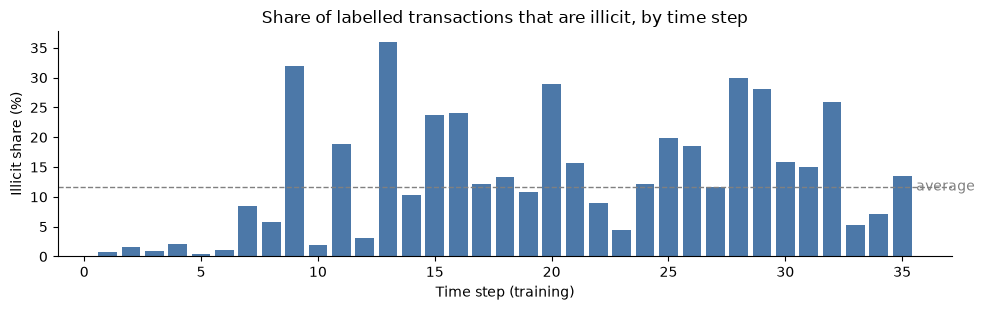

Overall illicit share: 11.7% (lowest step 0.4%, highest 36.0%)


In [4]:
by_step = known.groupby("time_step")["label"].agg(labelled="size", illicit="sum")
by_step["illicit share (%)"] = 100 * by_step["illicit"] / by_step["labelled"]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(by_step.index, by_step["illicit share (%)"], color="#4C78A8")
ax.axhline(100 * known["label"].mean(), color="grey", linestyle="--", linewidth=1)
ax.text(35.6, 100 * known["label"].mean(), "average", va="center", color="grey")
ax.set_xlabel("Time step (training)")
ax.set_ylabel("Illicit share (%)")
ax.set_title("Share of labelled transactions that are illicit, by time step")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Overall illicit share: {100 * known['label'].mean():.1f}% "
      f"(lowest step {by_step['illicit share (%)'].min():.1f}%, highest {by_step['illicit share (%)'].max():.1f}%)")

## 4. Feature preparation

This section decides which features each model sees.

### 4.1 Removing "calendar" features (for XGBoost only)

Some features rise and fall almost exactly with the time step. They act like a date printed on each page: a model could learn "early dates mean more fraud", which says nothing about future dates.

**What the next cell does:** measures how closely each feature follows the time step, using rank correlation (1 = they always rise together, 0 = no link), and lists the features above 0.9. These six are removed from XGBoost only. LightGBM keeps all 165, so the two models see the data from slightly different angles, which helps their average. The list is always worked out from the training rows only, never from the test rows.

In [5]:
def time_correlation(rows):
    # Spearman correlation = ordinary correlation between ranks
    return rows[FEATURES].rank().corrwith(rows["time_step"].rank())


def find_calendar_features(rows, threshold=0.9):
    corr = time_correlation(rows)
    return sorted(corr[corr.abs() > threshold].index, key=lambda c: int(c.split("_")[1]))


calendar = find_calendar_features(known)
print(f"{len(calendar)} calendar features removed from XGBoost:", calendar)
time_correlation(known)[calendar].round(3).rename("rank correlation with time step").to_frame()

6 calendar features removed from XGBoost: ['feat_100', 'feat_101', 'feat_103', 'feat_136', 'feat_137', 'feat_139']


,rank correlation with time step
feat_100,0.983
feat_101,0.998
feat_103,0.990
feat_136,0.993
feat_137,0.910
feat_139,0.959


### 4.2 Network features (for XGBoost only)

The payment links ("who paid whom") turn the data into a network. A broad set of network measures (how many links a transaction has, triangles, clustering, and PageRank, which measures how "central" a transaction is) made the practice exams worse by about 0.005. Two reasons: features 94–165 already describe each transaction's neighbours, and the network is full of holes.

**What the next cell does:** measures those holes. About two-thirds of the links around test transactions point to transactions that are in no file. It also shows *which* transactions are missing: their partners all sit in steps 36–49, and there are 46,668 of them, which matches the number of unlabelled test-period transactions in the original public dataset.

In [6]:
in_files = set(train["txId"]) | set(test["txId"])
test_ids = set(test["txId"])

touches_test = edges[edges["txId1"].isin(test_ids) | edges["txId2"].isin(test_ids)]
other_end = np.where(touches_test["txId1"].isin(test_ids), touches_test["txId2"], touches_test["txId1"])
missing_share = (~pd.Series(other_end).isin(in_files)).mean()

linked_test = len(test_ids & (set(edges["txId1"]) | set(edges["txId2"])))
print(f"Links touching a test transaction: {len(touches_test):,}")
print(f"Share whose other end is missing from the files: {missing_share:.0%}")
print(f"Test transactions with at least one link: {linked_test:,} of {len(test):,}")

# Which transactions are missing? Their link partners tell us their time period.
all_ids = set(edges["txId1"]) | set(edges["txId2"])
missing_ids = all_ids - in_files
step_of = pd.concat([train.set_index("txId")["time_step"], test.set_index("txId")["time_step"]])
partner_steps = pd.concat([
    edges.loc[edges["txId1"].isin(missing_ids), "txId2"],
    edges.loc[edges["txId2"].isin(missing_ids), "txId1"],
]).map(step_of).dropna()
print(f"Transactions in the network: {len(all_ids):,}; in our files: {len(in_files):,}; missing: {len(missing_ids):,}")
print(f"Time steps of the missing transactions' partners in our files: {int(partner_steps.min())}-{int(partner_steps.max())}")

Links touching a test transaction: 36,969
Share whose other end is missing from the files: 66%
Test transactions with at least one link: 15,329 of 15,329
Transactions in the network: 203,769; in our files: 157,101; missing: 46,668
Time steps of the missing transactions' partners in our files: 36-49


**Two small feature groups that I kept**

1. **Nine network counts (used in my best model).** For every transaction: incoming links, outgoing links, distinct partners, transactions reachable in two steps, the partners' own link counts (average and largest, plus average incoming and outgoing), and the share of partners that are "chain links" (exactly one input and one output, a common pattern when money is passed along). No labels are used, and none of the counts follows the time step. They tie on the practice exams but raised the public score to 0.95524 (+0.0004).
2. **Seven labelled-neighbour counts (used in my second selection).** Because the missing transactions are exactly the unlabelled test-period ones, I can count how many of a transaction's partners carry a label, in the same way for training and test. Only *whether* a partner has a label is used, never what that label is. Training transactions with no labelled partner are illicit 24% of the time against 8% for the rest, but the other features already carry most of this, so this group also ties (0.95499 on Kaggle).

**What the next cell does:** builds both groups from the payment links, attaches them to the training and test rows, and prints the 24% vs 8% comparison plus a short summary of each count.

In [7]:
# ---- Group 1: nine network counts (no labels used) ----
ids = pd.Index(pd.unique(np.r_[edges["txId1"].values, edges["txId2"].values, train["txId"].values, test["txId"].values]))
n = len(ids)
# A is a big grid with one row and one column per transaction: A[i, j] = 1 if transaction i paid transaction j
A = sp.csr_matrix((np.ones(len(edges)), (ids.get_indexer(edges["txId1"]), ids.get_indexer(edges["txId2"]))), shape=(n, n))
U = ((A + A.T) > 0).astype(float).tocsr()            # links in either direction
g_out = np.asarray(A.sum(1)).ravel()                 # outgoing links
g_in = np.asarray(A.sum(0)).ravel()                  # incoming links
g_deg = np.asarray(U.sum(1)).ravel()                 # distinct partners
two_step = U @ U
two_step.setdiag(0)
two_step.eliminate_zeros()
g_hop2 = np.asarray((two_step > 0).sum(1)).ravel()   # transactions reachable in two steps
safe = np.maximum(g_deg, 1)
# largest link count among each transaction's partners
partner_max = np.array([g_deg[U.indices[U.indptr[i]:U.indptr[i + 1]]].max() if U.indptr[i + 1] > U.indptr[i] else 0
                        for i in range(n)])
chain = ((g_in == 1) & (g_out == 1)).astype(float)   # "chain link": exactly one input and one output
network = pd.DataFrame({
    "g_in": g_in, "g_out": g_out, "g_deg": g_deg, "g_hop2": g_hop2,
    "g_nbdeg_mean": np.asarray(U @ g_deg).ravel() / safe, "g_nbdeg_max": partner_max,
    "g_nb_chain": np.asarray(U @ chain).ravel() / safe,
    "g_nb_out": np.asarray(U @ g_out).ravel() / safe, "g_nb_in": np.asarray(U @ g_in).ravel() / safe,
}, index=pd.Index(ids, name="txId"))

# ---- Group 2: labelled-neighbour counts (label presence only, never label values) ----
has_label = set(known["txId"]) | set(test["txId"])
links = edges.rename(columns={"txId1": "sender", "txId2": "receiver"})
links["sender_labelled"] = links["sender"].isin(has_label).astype(int)
links["receiver_labelled"] = links["receiver"].isin(has_label).astype(int)
outgoing = links.groupby("sender").agg(out_n=("receiver_labelled", "size"), out_lab=("receiver_labelled", "sum"))
incoming = links.groupby("receiver").agg(in_n=("sender_labelled", "size"), in_lab=("sender_labelled", "sum"))
lab = outgoing.join(incoming, how="outer").fillna(0)
labelled = pd.DataFrame({
    "l_in_lab": lab["in_lab"], "l_in_unl": lab["in_n"] - lab["in_lab"],
    "l_out_lab": lab["out_lab"], "l_out_unl": lab["out_n"] - lab["out_lab"],
})
labelled["l_nb_lab"] = labelled["l_in_lab"] + labelled["l_out_lab"]
labelled["l_nb_unl"] = labelled["l_in_unl"] + labelled["l_out_unl"]
labelled["l_nb_lab_frac"] = labelled["l_nb_lab"] / np.maximum(labelled["l_nb_lab"] + labelled["l_nb_unl"], 1)
labelled.index.name = "txId"

EXTRA_GROUPS = {None: [], "network": list(network.columns), "labelled": list(labelled.columns)}
known = known.join(network, on="txId").join(labelled, on="txId")
test = test.join(network, on="txId").join(labelled, on="txId")
known[EXTRA_GROUPS["labelled"]] = known[EXTRA_GROUPS["labelled"]].fillna(0)
test[EXTRA_GROUPS["labelled"]] = test[EXTRA_GROUPS["labelled"]].fillna(0)

no_labelled_partner = known["l_nb_lab"] == 0
print(f"Illicit share, training transactions with no labelled partner: {known.loc[no_labelled_partner, 'label'].mean():.1%} "
      f"({no_labelled_partner.sum():,} rows); with at least one: {known.loc[~no_labelled_partner, 'label'].mean():.1%}")
print("Largest rank correlation of a network count with the time step:",
      round(known[EXTRA_GROUPS["network"]].rank().corrwith(known["time_step"].rank()).abs().max(), 2))
known[EXTRA_GROUPS["network"] + EXTRA_GROUPS["labelled"]].describe().T[["mean", "50%", "max"]].round(2)

Illicit share, training transactions with no labelled partner: 24.4% (6,799 rows); with at least one: 8.1%
Largest rank correlation of a network count with the time step: 0.12


,mean,50%,max
g_in,1.76,1.00,284.0
g_out,1.10,1.00,472.0
g_deg,2.87,2.00,473.0
g_hop2,26.44,5.00,643.0
g_nbdeg_mean,15.88,3.33,473.0
g_nbdeg_max,24.22,4.00,473.0
g_nb_chain,0.19,0.00,1.0
g_nb_out,8.34,1.17,472.0
g_nb_in,7.54,1.25,284.0
l_in_lab,0.77,0.00,61.0


### 4.3 Recency weights

**Recency weighting** lets recent training transactions count more than old ones. Each transaction gets the weight

$$\text{weight} = 0.5^{(\text{latest step} - \text{its step}) / \text{half-life}}$$

With a half-life of 4, a transaction from step 31 counts half as much as one from step 35, and one from step 27 a quarter as much. It works like a weather forecaster who trusts last week more than last year.

**What the next cell does:** defines this weighting and shows, for several half-lives, how much of the total weight lands on the last seven training steps (29–35) and the **effective number of rows**: roughly, how many equally weighted rows the weighted data is worth. Stronger recency focuses on recent data but effectively throws data away: at half-life 4, the 31,235 rows are worth about 8,770.

In [8]:
def recency_weights(time_steps, half_life):
    # Weight for each training row; None means no recency weighting (all rows count equally)
    if half_life is None:
        return np.ones(len(time_steps))
    age = time_steps.max() - time_steps
    weights = 0.5 ** (age / half_life)
    return (weights / weights.mean()).to_numpy()


def effective_rows(weights):
    return weights.sum() ** 2 / (weights ** 2).sum()


rows = []
for half_life in [None, 7, 5, 4, 3]:
    w = recency_weights(known["time_step"], half_life)
    illicit = known["label"].to_numpy() == 1
    rows.append({
        "Half-life": "none" if half_life is None else half_life,
        "Weight on steps 29-35 (%)": round(100 * w[known["time_step"].to_numpy() >= 29].sum() / w.sum(), 1),
        "Effective rows": round(effective_rows(w)),
        "Effective illicit rows": round(effective_rows(w[illicit])),
    })
pd.DataFrame(rows).set_index("Half-life")

,Weight on steps 29-35 (%),Effective rows,Effective illicit rows
Half-life,,,
none,19.3,31235,3644
7,55.4,15107,2279
5,67.5,10969,1790
4,75.7,8770,1488
3,85.2,6593,1146


## 5. The two models

Both models are **gradient boosting** models: they build small decision trees one after another, each new tree fixing the mistakes of the trees before it, like a relay of tutors where each one focuses on the questions the last one got wrong. I use both libraries, which grow their trees slightly differently, and average their scores 50/50.

| Setting | XGBoost | LightGBM | Plain meaning |
|---|---|---|---|
| Boosting type | DART | standard | DART randomly switches off some earlier trees while each new tree is built |
| Trees | 300 | 150 | How many tutors in the relay |
| Learning rate | 0.05 | 0.05 | How much each new tree may change the score (small = careful) |
| Leaves per tree | 15 | 15 | How many end points each flowchart has (small trees = simple rules) |
| Value bins | 127 | 63 | Numbers are grouped into this many buckets before splitting (coarser = less noise) |
| Brakes: smallest group per leaf | weight 1 | 5 rows | A rule must be supported by at least this much data |
| Brakes: penalty (`reg_lambda`) | 1 | 1 | Shrinks extreme scores |
| Features | 159 (no calendar features) + 9 network counts | 165 | |

**Why light brakes?** Early on I used heavy brakes (each rule needed more data, plus a penalty of 10). They stopped the model from learning small groups of illicit transactions, such as small fraud rings, and lost to the lighter settings in 13 of 15 practice exams.

**Why no re-balancing?** Only about 12% of labelled rows are illicit. ROC-AUC only judges the order of the scores, so I leave the classes as they are: giving illicit rows 7.6 times the weight lowered the practice-exam average by about 0.009, and creating synthetic illicit rows (SMOTE) by about 0.004.

**Why 300 XGBoost trees?** With strong recency weighting, XGBoost needed a few more trees to finish learning: 300 beat 200 in 11 of 15 practice exams, while extra LightGBM trees hurt. The recency comparison in Section 6 keeps the 200 trees it was first run (and uploaded) with.

**Why DART?** In ordinary boosting the first trees do most of the work and later trees only patch small mistakes. DART switches off a random 10% of the existing trees (half the time) while each new tree is built, so every tree has to stay useful on its own, like a team where anyone may be absent and the others must cover. On its own, DART XGBoost beat ordinary XGBoost on the practice exams; averaged with LightGBM it ties (Section 6.1), and on Kaggle it scored 0.95527 against 0.95524. DART in LightGBM was much worse, so LightGBM stays standard.

**What the next cell does:** defines the two models with the settings above; a helper, `train_pair`, that trains both on the given rows and averages their scores 50/50; and the simple baseline, logistic regression, which gives each feature a fixed weight and adds them up like a checklist score.

In [9]:
def make_xgb(n_trees=FINAL_XGB_TREES, dart=FINAL_XGB_DART):
    settings = dict(
        n_estimators=n_trees, learning_rate=0.05, tree_method="hist", grow_policy="lossguide",
        max_depth=0, max_leaves=15, max_bin=127, min_child_weight=1, reg_lambda=1,
        objective="binary:logistic", n_jobs=THREADS, random_state=SEED,
    )
    if dart:
        # DART: while each new tree is built, switch off a random 10% of the earlier trees (skipped half the time)
        settings.update(booster="dart", rate_drop=0.1, skip_drop=0.5, sample_type="uniform", normalize_type="tree")
    return XGBClassifier(**settings)


def make_lgb():
    return LGBMClassifier(
        n_estimators=150, learning_rate=0.05, num_leaves=15, max_bin=63, min_child_samples=5,
        min_child_weight=1e-3, reg_lambda=1, objective="binary", deterministic=True,
        force_col_wise=True, verbosity=-1, n_jobs=THREADS, random_state=SEED,
    )


def train_pair(rows, half_life=FINAL_HALF_LIFE, xgb_trees=FINAL_XGB_TREES, extra=XGB_EXTRA, dart=FINAL_XGB_DART):
    # Train both models on `rows` and return a function that scores new rows.
    # `extra` names a feature group from Section 4.2 that only XGBoost receives; `dart` switches XGBoost to DART.
    weights = recency_weights(rows["time_step"], half_life)
    calendar_features = find_calendar_features(rows)   # computed from the training rows only
    xgb_features = [c for c in FEATURES if c not in calendar_features] + EXTRA_GROUPS[extra]
    xgb = make_xgb(xgb_trees, dart).fit(rows[xgb_features], rows["label"], sample_weight=weights)
    lgb = make_lgb().fit(rows[FEATURES], rows["label"], sample_weight=weights)

    def score(new_rows):
        return (0.5 * xgb.predict_proba(new_rows[xgb_features])[:, 1]
                + 0.5 * lgb.predict_proba(new_rows[FEATURES])[:, 1])

    return score


def train_baseline(rows):
    # Simple baseline: logistic regression on the standardised features
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    model.fit(rows[FEATURES], rows["label"])
    return lambda new_rows: model.predict_proba(new_rows[FEATURES])[:, 1]

## 6. Validation: 15 practice exams

**Why split by time?** Ordinary cross-validation shuffles rows into random groups, so the model would learn from transactions in the same time step as the ones it is tested on. That is like practising with questions from the very paper you will sit, so I always split by time. But a single time split can also mislead: my first model scored 0.995 when tested on steps 29–35 and then 0.937 on Kaggle, because that one period happened to be easy.

**Practice exams.** This is basically back-testing: each exam hides the future. The model learns from steps 1 to *k* and is tested on the next 14 steps, for *k* = 7, 8, …, 21. That gives 15 exams, and the local score is their average ROC-AUC. I checked this yardstick against real Kaggle results: it put five ordinary models in the same order as Kaggle, so it is a reliable **compass** (which direction is better), but only about a third of a local gain carried over, so it is not a reliable **ruler** (by how much).

**What the next cell does:** runs the 15 exams for nine versions: the baseline; the two-model average without recency and with half-lives 7, 5, 4 and 3 (all with the original 200 XGBoost trees); and the half-life 4 model with 300 trees, alone and with each feature group from Section 4.2. All of these use ordinary XGBoost; DART is checked separately in Section 6.1 because it is much slower. It prints one row per exam and one column per version, and takes about 9 minutes.

In [10]:
EXAMS = [(k, k + 1, k + 14) for k in range(7, 22)]   # (last training step, first exam step, last exam step)


def practice_exams(trainer, **settings):
    results = {}
    for last_train, first_exam, last_exam in EXAMS:
        learn = known[known["time_step"] <= last_train]
        exam = known[known["time_step"].between(first_exam, last_exam)]
        score = trainer(learn, **settings)
        results[f"{first_exam}-{last_exam}"] = roc_auc_score(exam["label"], score(exam))
    return pd.Series(results)


start = time.time()
recipes = {
    "Baseline: logistic regression": (train_baseline, {}),
    "Two-model average, no recency": (train_pair, {"half_life": None, "xgb_trees": 200, "extra": None, "dart": False}),
    "Two-model average, half-life 7": (train_pair, {"half_life": 7, "xgb_trees": 200, "extra": None, "dart": False}),
    "Two-model average, half-life 5": (train_pair, {"half_life": 5, "xgb_trees": 200, "extra": None, "dart": False}),
    "Two-model average, half-life 4": (train_pair, {"half_life": 4, "xgb_trees": 200, "extra": None, "dart": False}),
    "Two-model average, half-life 3": (train_pair, {"half_life": 3, "xgb_trees": 200, "extra": None, "dart": False}),
    "Half-life 4, 300 XGBoost trees": (train_pair, {"half_life": 4, "xgb_trees": 300, "extra": None, "dart": False}),
    "Half-life 4, 300 trees + network counts": (train_pair, {"half_life": 4, "xgb_trees": 300, "extra": "network", "dart": False}),
    "Half-life 4, 300 trees + labelled-neighbour counts": (train_pair, {"half_life": 4, "xgb_trees": 300, "extra": "labelled", "dart": False}),
}
exam_results = pd.DataFrame({name: practice_exams(fn, **kw) for name, (fn, kw) in recipes.items()})
print(f"Practice exams finished in {time.time() - start:.0f} seconds")
exam_results.round(4)

Practice exams finished in 429 seconds


,Baseline: logistic regression,"Two-model average, no recency","Two-model average, half-life 7","Two-model average, half-life 5","Two-model average, half-life 4","Two-model average, half-life 3","Half-life 4, 300 XGBoost trees","Half-life 4, 300 trees + network counts","Half-life 4, 300 trees + labelled-neighbour counts"
8-21,0.9367,0.9931,0.9933,0.9931,0.9940,0.9937,0.9940,0.9940,0.9940
9-22,0.9354,0.9937,0.9946,0.9942,0.9943,0.9942,0.9945,0.9944,0.9947
10-23,0.9470,0.9921,0.9926,0.9924,0.9923,0.9922,0.9924,0.9923,0.9924
11-24,0.9372,0.9772,0.9778,0.9761,0.9735,0.9713,0.9739,0.9735,0.9732
12-25,0.9355,0.9760,0.9759,0.9686,0.9721,0.9668,0.9706,0.9703,0.9684
13-26,0.9275,0.9697,0.9743,0.9720,0.9729,0.9725,0.9730,0.9728,0.9729
14-27,0.9205,0.9714,0.9758,0.9735,0.9740,0.9747,0.9732,0.9738,0.9740
15-28,0.9203,0.9720,0.9738,0.9754,0.9706,0.9730,0.9715,0.9717,0.9714
16-29,0.8918,0.9375,0.9373,0.9456,0.9359,0.9325,0.9399,0.9405,0.9410
17-30,0.8813,0.9462,0.9496,0.9466,0.9395,0.9398,0.9399,0.9390,0.9412


**What the next cell does:** draws three of the versions across the 15 exams, then lists each version's average score and how many of the 15 exams it beat the 300-tree half-life 4 model on.

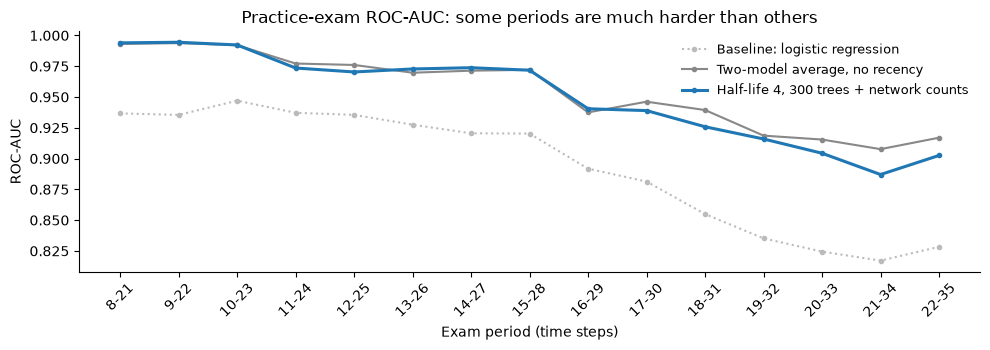

,Average of 15 exams,Exams better than 300-tree half-life 4
Baseline: logistic regression,0.8929,0
"Two-model average, no recency",0.9551,9
"Two-model average, half-life 7",0.9561,13
"Two-model average, half-life 5",0.9536,11
"Two-model average, half-life 4",0.9499,4
"Two-model average, half-life 3",0.9472,2
"Half-life 4, 300 XGBoost trees",0.9507,
"Half-life 4, 300 trees + network counts",0.9505,5
"Half-life 4, 300 trees + labelled-neighbour counts",0.9507,8


In [11]:
fig, ax = plt.subplots(figsize=(10, 3.6))
styles = {
    "Baseline: logistic regression": dict(color="#BBBBBB", linestyle=":"),
    "Two-model average, no recency": dict(color="#888888"),
    "Half-life 4, 300 trees + network counts": dict(color="#1F77B4", linewidth=2.2),
}
for name, style in styles.items():
    ax.plot(exam_results.index, exam_results[name], marker="o", markersize=3, label=name, **style)
ax.set_ylabel("ROC-AUC")
ax.set_xlabel("Exam period (time steps)")
ax.set_title("Practice-exam ROC-AUC: some periods are much harder than others")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

summary = exam_results.mean().round(4).rename("Average of 15 exams").to_frame()
reference = exam_results["Half-life 4, 300 XGBoost trees"]
summary["Exams better than 300-tree half-life 4"] = [int((exam_results[c] > reference).sum()) if c != reference.name else "" for c in exam_results]
summary

### 6.1 DART check

DART makes training much slower, because every time a tree is added the model re-scores the data with a random set of earlier trees switched off. So this check is shown from my recorded run by default (`RUN_DART_EXAMS = False`) and can be re-run in full by setting `RUN_DART_EXAMS = True` in Section 1. 

**What the next cell does:** compares the half-life 4 model with network counts, using ordinary XGBoost (from the exams above) and DART XGBoost, on the same 15 exams. The two average 0.9505 and 0.9498: a tie, with DART ahead in 4 of 15 exams. DART was kept because it scored slightly higher on Kaggle (0.95527 against 0.95524), a gap far too small to prove anything; the two versions are my two final selections.

In [12]:
# Recorded ROC-AUC of the DART version on each exam (half-life 4, 300 trees, network counts, DART XGBoost + LightGBM)
DART_RECORDED = {
    "8-21": 0.993937,
    "9-22": 0.994084,
    "10-23": 0.992199,
    "11-24": 0.974103,
    "12-25": 0.972271,
    "13-26": 0.971629,
    "14-27": 0.975045,
    "15-28": 0.970071,
    "16-29": 0.935057,
    "17-30": 0.937999,
    "18-31": 0.925503,
    "19-32": 0.91292,
    "20-33": 0.899944,
    "21-34": 0.886738,
    "22-35": 0.904862,
}

plain_name = "Half-life 4, 300 trees + network counts"
if RUN_DART_EXAMS:
    start = time.time()
    dart_scores = practice_exams(train_pair, half_life=4, xgb_trees=300, extra="network", dart=True)
    print(f"DART practice exams finished in {time.time() - start:.0f} seconds")
else:
    dart_scores = pd.Series(DART_RECORDED)
    print("Showing the recorded DART results (set RUN_DART_EXAMS = True in Section 1 to re-run them).")

dart_check = pd.DataFrame({"Ordinary XGBoost": exam_results[plain_name], "DART XGBoost": dart_scores})
dart_check.loc["Average of 15 exams"] = dart_check.mean()
print("Exams where DART is higher:", int((dart_scores > exam_results[plain_name]).sum()), "of 15")
dart_check.round(4)

Showing the recorded DART results (set RUN_DART_EXAMS = True in Section 1 to re-run them).
Exams where DART is higher: 4 of 15


,Ordinary XGBoost,DART XGBoost
8-21,0.9940,0.9939
9-22,0.9944,0.9941
10-23,0.9923,0.9922
11-24,0.9735,0.9741
12-25,0.9703,0.9723
13-26,0.9728,0.9716
14-27,0.9738,0.9750
15-28,0.9717,0.9701
16-29,0.9405,0.9351
17-30,0.9390,0.9380


**Analysing the practice exams**

- The two-model average beats the logistic-regression baseline in every period, and by a wide margin in the hard ones.
- Some periods are far harder than others. These are periods where illicit behaviour changed, so patterns from earlier steps no longer fit.
- Here, mild recency (half-life 7) is about equal to none, and stronger recency is *worse*. That is expected: all the exams fall inside steps 1–35, where no dark market shutdown happens, so older data stays useful and strong recency mostly throws data away.

**Why the recency strength was chosen on Kaggle.** The test period (steps 36–49) contains the shutdown, which the practice exams cannot imitate. So for this one question I let Kaggle provide greater clarity, uploading one recency strength at a time. These are the public scores, typed in from the Kaggle leaderboard:

| Version | Kaggle public ROC-AUC |
|---|---|
| Two-model average, no recency | 0.94701 |
| Half-life 7 | 0.94989 |
| Half-life 5 | 0.95154 |
| Half-life 4 | 0.95471 |
| Half-life 3 | 0.95270 |
| Half-life 4, 300 XGBoost trees | 0.95484 |
| Half-life 4, 300 trees + labelled-neighbour counts | 0.95499 |
| Half-life 4, 300 trees + network counts (second selection) | 0.95524 |
| **Same, XGBoost with DART (final model)** | **0.95527** |

Kaggle rises with stronger recency up to a half-life of 4, then falls at 3, where losing data (Section 4.3) outweighs the gain in relevance. Half-life 5 scoring below both of its neighbours suggests half-life 4 was also a little lucky on the public 30% of test rows, by roughly 0.002.

**The last four rows are ties.** More trees, the two feature groups and DART each move the Kaggle score by less than 0.0005. Splitting the practice exams 30/70 like Kaggle, the same model's public and private scores differ by about ±0.007–0.009 by chance, so gaps this small are noise. I therefore chose my two final selections simply as my two highest public scores.

**Earlier lesson: a method can pass the exams and still fail.** A "look-alike" model that compared test transactions with each other scored 0.9713 on the practice exams but 0.87805 on Kaggle. Since then I also compare every candidate's ranking of the test rows with my best model before uploading (Section 7).

## 7. Final model: train on all labelled data and score the test set

**What the next cell does:** trains the final model on all 31,235 labelled training transactions (steps 1–35) with half-life 4, 300 DART XGBoost trees with the nine network counts, and LightGBM, then scores the 15,329 test transactions. The unknown rows are not used. Training takes a few minutes because of DART.

As a **safety check**, it also trains the pair without recency (and with ordinary XGBoost) and compares the two rankings of the test rows. A sensible change keeps most of the ranking (high agreement) while moving some rows. A ranking turned upside down would be a warning sign, as it was for the look-alike model.

In [13]:
start = time.time()
final_score = train_pair(known)   # half-life FINAL_HALF_LIFE, FINAL_XGB_TREES trees, extra group XGB_EXTRA, DART if FINAL_XGB_DART
test_pred = final_score(test)
print(f"Final model trained and test set scored in {time.time() - start:.1f} seconds")
print("XGBoost uses", len(FEATURES) - len(find_calendar_features(known)) + len(EXTRA_GROUPS[XGB_EXTRA]),
      "features; LightGBM uses", len(FEATURES))

no_recency_pred = train_pair(known, half_life=None, extra=None, dart=False)(test)
top = int(round(0.06 * len(test)))   # the 6% most suspicious test rows
rank_final = pd.Series(test_pred).rank(ascending=False)
rank_old = pd.Series(no_recency_pred).rank(ascending=False)
safety = {
    "Rank agreement with no-recency model (1 = same order)": round(rank_final.corr(rank_old), 3),
    f"Overlap of the top {top} most suspicious rows": f"{((rank_final <= top) & (rank_old <= top)).sum() / top:.0%}",
    "Final top rows that the old model ranked in its bottom half": f"{(rank_old[rank_final <= top] > len(test) / 2).mean():.1%}",
}
pd.Series(safety, name="Safety check").to_frame()

Final model trained and test set scored in 496.0 seconds


XGBoost uses 168 features; LightGBM uses 165


,Safety check
Rank agreement with no-recency model (1 = same order),0.94
Overlap of the top 920 most suspicious rows,83%
Final top rows that the old model ranked in its bottom half,0.0%


## 8. Submission file

**What the next cell does:** puts the scores into Kaggle's format (two columns, `index` and `target`, in the sample's row order, where `target` is the suspicion score between 0 and 1), checks the file, and saves it as `submissions/e1156285_submission.csv`. If the copy I uploaded to Kaggle (`submission_xgbdart.csv`) is in the project folder, it then compares the two: a largest difference around 1e-16 means the two are identical apart from the computer's rounding.

In [14]:
submission = sample[["index"]].copy()
submission["target"] = submission["index"].map(pd.Series(test_pred, index=test["index"]))

assert list(submission.columns) == ["index", "target"]
assert len(submission) == len(sample) == 15329
assert submission["index"].equals(sample["index"]), "row order must match the sample submission"
assert submission["target"].notna().all() and submission["target"].between(0, 1).all()

final_path = OUTPUT_DIR / "e1156285_submission.csv"
submission.to_csv(final_path, index=False)
print("Saved", final_path.relative_to(PROJECT_DIR))

# Name of the copy uploaded to Kaggle for each choice of (XGB_EXTRA, FINAL_XGB_DART)
UPLOADED = {("network", True): "submission_xgbdart.csv", ("network", False): "submission_graphshape_xgb.csv",
            (None, False): "submission_half4_long_xgb_300_150_experimental.csv", ("labelled", False): "submission_labnb_xgb.csv"}


def compare_with_uploaded(new, file_name):
    # If the copy uploaded to Kaggle is in the project folder, report the largest difference
    for folder in ["submissions", "archive/results/claude_experiments/submissions", "archive/results/half4_longer_training_results"]:
        uploaded_path = PROJECT_DIR / folder / file_name
        if uploaded_path.exists():
            uploaded = pd.read_csv(uploaded_path)
            gap = (uploaded["target"] - new["target"]).abs().max()
            print(f"Largest difference from the uploaded file ({folder}/{file_name}): {gap:.1e}")
            return gap


if (XGB_EXTRA, FINAL_XGB_DART) in UPLOADED:
    compare_with_uploaded(submission, UPLOADED[(XGB_EXTRA, FINAL_XGB_DART)])
submission.head()

Saved submissions/e1156285_submission.csv
Largest difference from the uploaded file (archive/results/claude_experiments/submissions/submission_xgbdart.csv): 1.1e-16


,index,target
0,0,0.000456
1,1,0.002767
2,2,0.001567
3,3,0.001746
4,4,0.001332


## 9. Second final selection: the same model without DART

Kaggle ranks each student on the hidden 70% of the test rows (the private leaderboard), using the better of two submissions that the student picks. I picked my two highest public scores: the final model above (0.95527), and the same model with ordinary XGBoost instead of DART (0.95524).

**What the next cell does:** trains that version, saves it as `submissions/e1156285_submission_second.csv`, shows how closely its ranking agrees with the final model's (1 = identical order), and, if the copy I uploaded (`submission_graphshape_xgb.csv`) is in the project folder, compares the two. Set `MAKE_SECOND_SELECTION = False` to skip this step.

In [15]:
MAKE_SECOND_SELECTION = True

if MAKE_SECOND_SELECTION:
    start = time.time()
    second_pred = train_pair(known, dart=False)(test)   # same model, ordinary XGBoost instead of DART

    second = sample[["index"]].copy()
    second["target"] = second["index"].map(pd.Series(second_pred, index=test["index"]))
    assert second["index"].equals(sample["index"]), "row order must match the sample submission"
    assert second["target"].notna().all() and second["target"].between(0, 1).all()

    second_path = OUTPUT_DIR / "e1156285_submission_second.csv"
    second.to_csv(second_path, index=False)
    print(f"Saved {second_path.relative_to(PROJECT_DIR)} in {time.time() - start:.1f} seconds")
    print("Rank agreement with the final model's file (1 = same order):",
          round(pd.Series(second_pred).rank().corr(pd.Series(test_pred).rank()), 4))
    compare_with_uploaded(second, "submission_graphshape_xgb.csv")

Saved submissions/e1156285_submission_second.csv in 7.0 seconds
Rank agreement with the final model's file (1 = same order): 0.9958
Largest difference from the uploaded file (archive/results/claude_experiments/submissions/submission_graphshape_xgb.csv): 1.1e-16


## 10. Summary

- **Final model:** XGBoost with DART (300 trees; 159 features without the six calendar features, plus nine network counts) and LightGBM (150 trees; all 165 features), both with light brakes, averaged 50/50 and trained on all labelled transactions with recency half-life 4.
- **Result:** best public ROC-AUC **0.95527**, up from 0.93654 for my first submission.
- **Final selections:** this model (0.95527) and the same model with ordinary XGBoost (0.95524), my two highest public scores.
- **Validation:** 15 forward-in-time practice exams for ordinary choices; Kaggle for the recency strength, because only the test period contains the dark market shutdown.

**AI assistance.** I used two AI assistants. OpenAI Codex (via ChatGPT) set up the repository and notebook and wrote and ran the baselines and early experiments. Anthropic's Claude proposed and coded the evaluation and the safety check, wrote and ran most later experiments, helped build this notebook and drafted the report. I set the goals, chose which candidates to upload, compared the two assistants' results and chose the final submissions. All experiments used the competition data only.